In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confusion-matrix

**Figure 2: Confusion matrix of the Random Forest classifier (500 trees, TF-IDF features) predicting Yelp star ratings on the test set.** Each row is normalized over its true rating, so the diagonal is per-class recall; values are as printed in the original (2 significant digits). Predictions skew toward the extremes: 1- and 5-star reviews are mostly classified correctly (0.82 and 0.76), but 2-star reviews are predicted as 1 star about as often as correctly (0.38 vs. 0.37), and 4-star reviews as 5 stars (0.37 vs. 0.39).

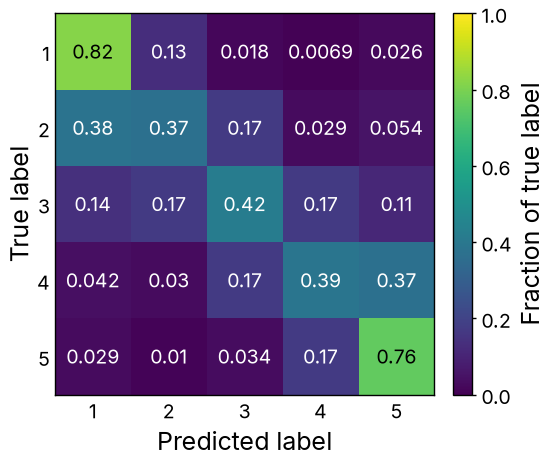

In [2]:
data = json.load(open("../data/confusion-matrix.json"))
matrix = np.array(data["matrix"])

fig, ax = plt.subplots(figsize=(2.75, 2.75))
im = ax.imshow(matrix, aspect="auto", vmin=0, vmax=1)
for i in range(len(data["labels"])):
    for j in range(len(data["labels"])):
        v = matrix[i, j]
        text_color = "white" if np.dot(im.cmap(im.norm(v))[:3], [0.299, 0.587, 0.114]) < 0.5 else "black"
        ax.text(j, i, f"{v:.2g}", ha="center", va="center", color=text_color)
ax.set_xticks(range(len(data["labels"])), labels=data["labels"])
ax.set_yticks(range(len(data["labels"])), labels=data["labels"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.tick_params(length=0)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Fraction of true label")
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/confusion-matrix.pdf")
fig.savefig("../outputs/confusion-matrix.png")
plt.show()